# 🌌 Jet Tagging: EFN + ArcFace (Advanced Analysis)
**Mission:** Professional evaluation of background rejection and latent space physics.

## 🛠️ 1. Environment & Git Sync
Paste your token below to pull the latest updates and plotting utilities.

In [1]:
import os
import sys

# === 🔑 GH TOKEN ===
GH_TOKEN = ""
# ===================

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_URL = f"https://{GH_TOKEN}@github.com/thirathep-ph/Jet-Tagging.git"
    if not os.path.exists('/content/Jet-Tagging'):
        !git clone {REPO_URL} /content/Jet-Tagging
    else:
        %cd /content/Jet-Tagging
        !git pull
    %cd /content/Jet-Tagging
    # Data Link
    DRIVE_DATA = '/content/drive/My Drive/Jet Tagging/Top Quark Tagging Reference Dataset'
    os.makedirs('data/top_tagging', exist_ok=True)
    if os.path.exists(DRIVE_DATA):
        !ln -sf "{DRIVE_DATA}/"* data/top_tagging/
    %pip install -e .
    %pip install hdf5plugin
else:
    print("Running on Local Machine.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/Jet-Tagging
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 10 (delta 4), reused 10 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (10/10), 5.50 KiB | 804.00 KiB/s, done.
From https://github.com/thirathep-ph/Jet-Tagging
   e3b1c73..143f005  main       -> origin/main
Updating e3b1c73..143f005
Fast-forward
 jet_tagging/utils/physics.py           |  27 +++
 jet_tagging/utils/plotting.py          | 144 ++++++++++++
 notebooks/TopTagging_EFN_ArcFace.ipynb | 401 ++++++---------------------------
 scripts/train_top.py                   |  33 ++-
 4 files changed, 278 insertions(+), 327 deletions(-)
 create mode 100644 jet_tagging/utils/plotting.py
/content/Jet-Tagging
Obtaining file:///content/Jet-Tagging
  Preparing metadata (setup.py) ... done
  At

## 🚀 2. Medium-Scale Training
Running 20k events for 10 epochs to evaluate initial physics patterns.

In [5]:
!python -u scripts/train_top.py --max_events 600000 --epochs 50

Loading data/top_tagging/train.h5...
  Reading 600,000 entries from data/top_tagging/train.h5...
  Pre-computing padded constituent arrays (600000 events)...
  Done in 17.69s
Loading data/top_tagging/val.h5...
  Reading 403,000 entries from data/top_tagging/val.h5...
  Pre-computing padded constituent arrays (403000 events)...
  Done in 8.64s
Loading data/top_tagging/test.h5...
  Reading 404,000 entries from data/top_tagging/test.h5...
  Pre-computing padded constituent arrays (404000 events)...
  Done in 11.23s

Training EFN + ArcFace (Params: 270,592)
Epoch  1: Train Loss=2.4299 Acc=0.8479 | Val Loss=0.5595 Acc=0.8854
Epoch  2: Train Loss=2.0964 Acc=0.8608 | Val Loss=0.5549 Acc=0.8867
Epoch  3: Train Loss=2.0593 Acc=0.8572 | Val Loss=0.5002 Acc=0.8872
Epoch  4: Train Loss=1.9946 Acc=0.8346 | Val Loss=0.4972 Acc=0.8818
Epoch  5: Train Loss=1.9435 Acc=0.8253 | Val Loss=0.4824 Acc=0.8804
Epoch  6: Train Loss=1.9219 Acc=0.8267 | Val Loss=0.4738 Acc=0.8808
Epoch  7: Train Loss=1.9111 Acc=

## 📊 3. Advanced Visualization
Displaying Latent Space Clustering, ROC Curves, and Jet Patterns.

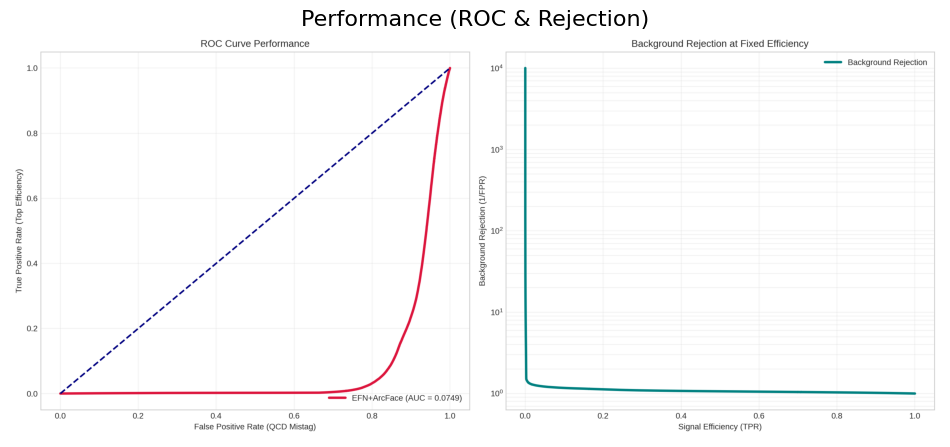

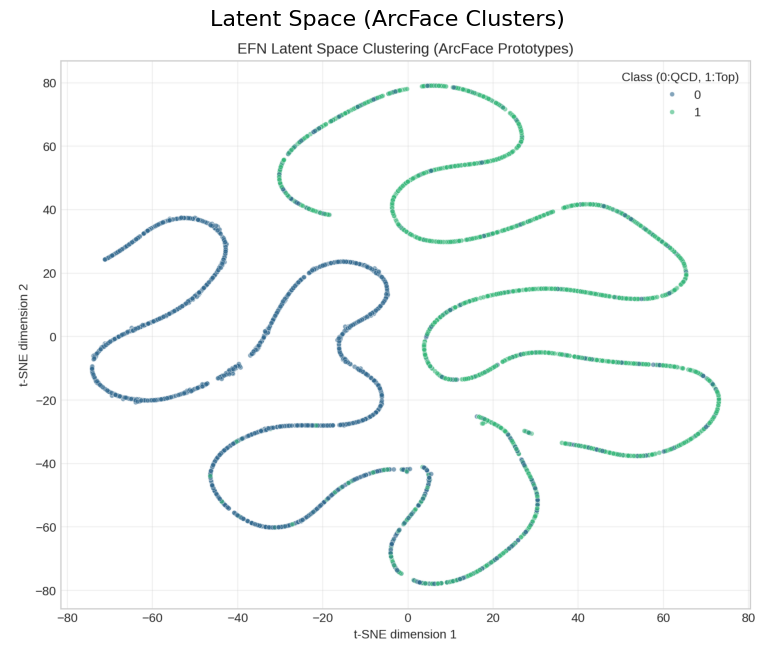

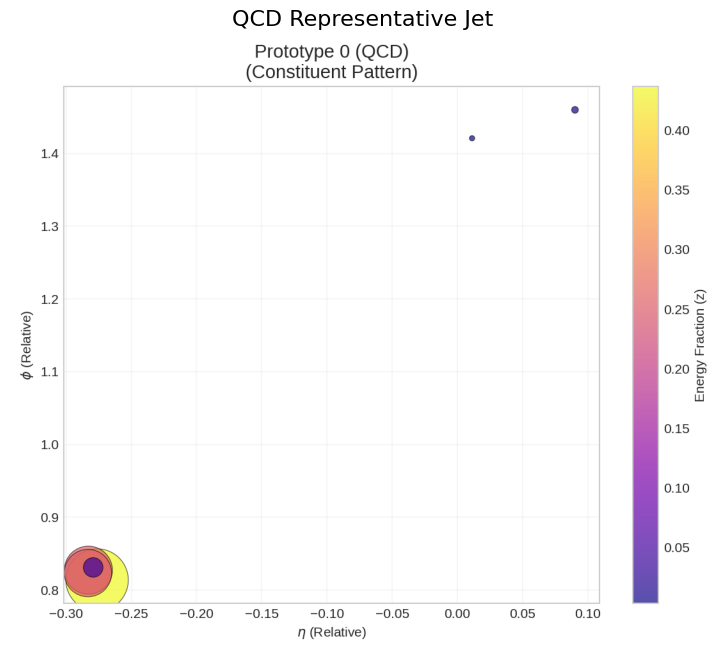

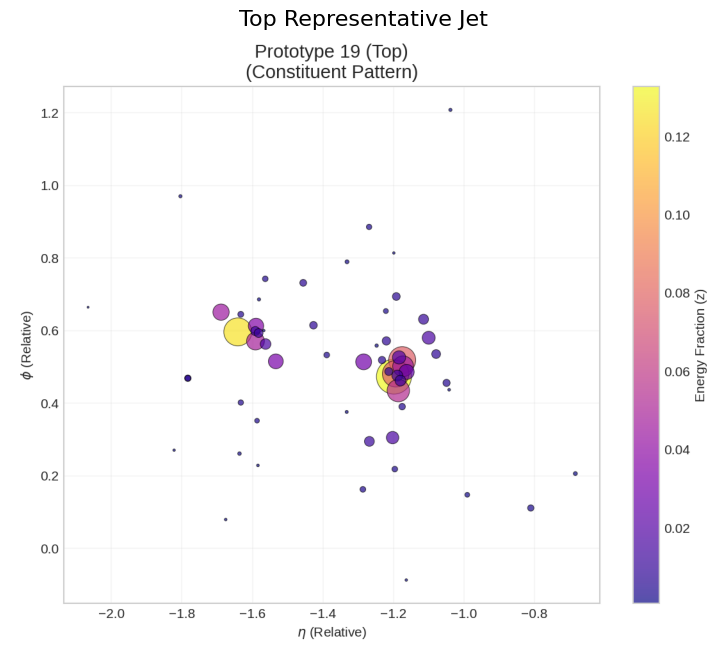

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import json

visuals = [
    ('results/performance.png', 'Performance (ROC & Rejection)'),
    ('results/latent_space.png', 'Latent Space (ArcFace Clusters)'),
    ('results/proto_0_jet.png', 'QCD Representative Jet'),
    ('results/proto_19_jet.png', 'Top Representative Jet')
]

for path, title in visuals:
    if os.path.exists(path):
        plt.figure(figsize=(12, 8))
        img = mpimg.imread(path)
        plt.imshow(img)
        plt.axis('off')
        plt.title(title, fontsize=16)
        plt.show()
    else:
        print(f"⚠️ Missing: {path}")

## 🧐 4. Physics Interpretability Summary

In [7]:
json_res = 'results/efn_results.json'
if os.path.exists(json_res):
    with open(json_res, 'r') as f:
        data = json.load(f)
    print(f"Found {len(data)} Prototype Interpretations:\n")
    for entry in data[:5]:
        f = entry['features']
        print(f"Proto {entry['proto_id']:2d} ({entry['proto_class']}): Event #{entry['event_idx']}")
        print(f"  -> Mass: {f[0]:.1f}, mSD: {f[1]:.1f}, Mult: {f[2]:.0f}, Tau32: {f[5]:.3f}")
        print("-" * 40)
else:
    print("❌ Results JSON not found.")

Found 20 Prototype Interpretations:

Proto  0 (QCD): Event #237435
  -> Mass: 40.3, mSD: 4.4, Mult: 6, Tau32: 0.213
----------------------------------------
Proto  1 (QCD): Event #14053
  -> Mass: 88.3, mSD: 9.2, Mult: 29, Tau32: 0.630
----------------------------------------
Proto  2 (QCD): Event #237435
  -> Mass: 40.3, mSD: 4.4, Mult: 6, Tau32: 0.213
----------------------------------------
Proto  3 (QCD): Event #237435
  -> Mass: 40.3, mSD: 4.4, Mult: 6, Tau32: 0.213
----------------------------------------
Proto  4 (QCD): Event #237435
  -> Mass: 40.3, mSD: 4.4, Mult: 6, Tau32: 0.213
----------------------------------------
